In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pickle
import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv(r"C:\Users\LENOVO\Downloads\Social_Media_Mental_Wellbeing.csv")
df.head()

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Social_Support_Score,Cyberbullying_Exposure,Social_Comparison_Level,Exercise_Days_Per_Week,Stress_Level,Mental_Health_Score
0,29,Female,United Kingdom,Undergraduate,Facebook,Entertainment,3.59,90,3.04,1.34,7.19,5.4,No,4,3,Medium,93.0
1,30,Non-binary,India,Undergraduate,TikTok,Communication,1.92,26,3.04,1.96,6.48,4.9,No,3,4,Medium,73.8
2,27,Male,India,Undergraduate,YouTube,Networking,2.20,77,1.35,1.17,7.89,5.7,No,3,1,Medium,86.6
3,27,Male,India,Undergraduate,Other,Mixed,2.99,48,4.72,1.15,4.61,6.9,No,2,5,Medium,96.7
4,29,Female,Australia,Postgraduate,Instagram,Entertainment,5.01,85,1.41,0.37,7.14,8.2,No,5,0,Medium,80.5


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      50000 non-null  int64  
 1   Gender                   50000 non-null  object 
 2   Country                  50000 non-null  object 
 3   Academic_Level           50000 non-null  object 
 4   Most_Used_Platform       50000 non-null  object 
 5   Purpose_Of_Use           50000 non-null  object 
 6   Avg_Daily_Usage_Hours    50000 non-null  float64
 7   Daily_Unlocks            50000 non-null  int64  
 8   Study_Hours              50000 non-null  float64
 9   Physical_Activity_Hours  50000 non-null  float64
 10  Sleep_Hours_Per_Night    50000 non-null  float64
 11  Social_Support_Score     50000 non-null  float64
 12  Cyberbullying_Exposure   50000 non-null  object 
 13  Social_Comparison_Level  50000 non-null  int64  
 14  Exercise_Days_Per_Week

In [4]:
df.isna().sum()

Age                        0
Gender                     0
Country                    0
Academic_Level             0
Most_Used_Platform         0
Purpose_Of_Use             0
Avg_Daily_Usage_Hours      0
Daily_Unlocks              0
Study_Hours                0
Physical_Activity_Hours    0
Sleep_Hours_Per_Night      0
Social_Support_Score       0
Cyberbullying_Exposure     0
Social_Comparison_Level    0
Exercise_Days_Per_Week     0
Stress_Level               0
Mental_Health_Score        0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

### Exploratory Data Analysis (EDA)

##### Target Variable Analysis

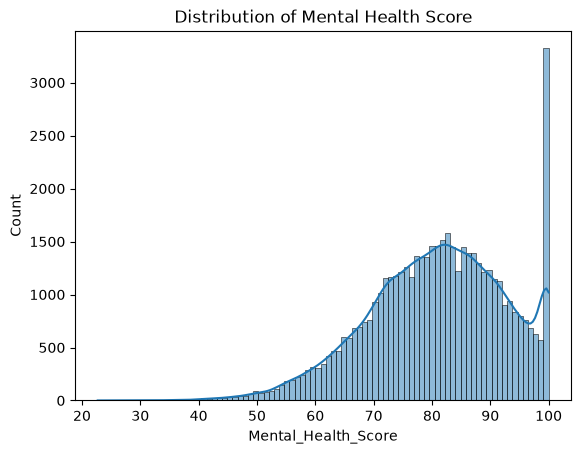

In [6]:
sns.histplot(df["Mental_Health_Score"], kde=True)
plt.title("Distribution of Mental Health Score")
plt.show()

##### Social Media Usage vs Mental Health Score

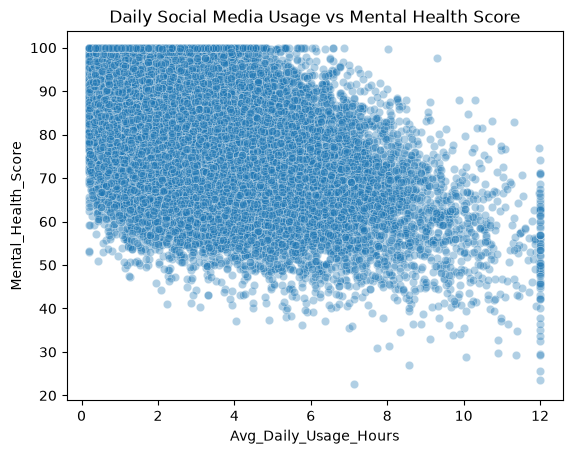

In [7]:
sns.scatterplot(x="Avg_Daily_Usage_Hours", y="Mental_Health_Score", data=df, alpha=0.35)
plt.title("Daily Social Media Usage vs Mental Health Score")
plt.show()

##### Sleep Hours vs Mental Health Score

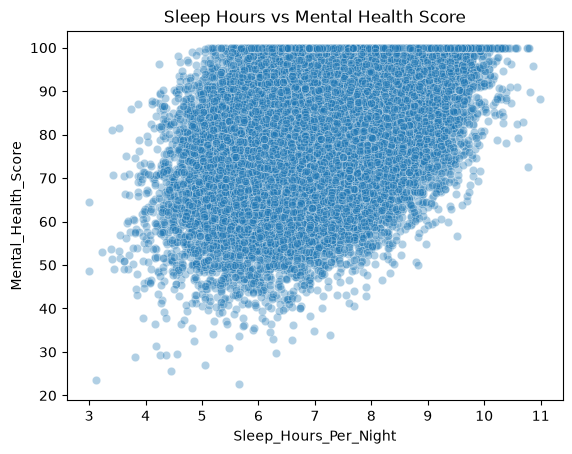

In [8]:
sns.scatterplot(x="Sleep_Hours_Per_Night", y="Mental_Health_Score", data=df, alpha=0.35)
plt.title("Sleep Hours vs Mental Health Score")
plt.show()

##### Correlation Between Numerical Features

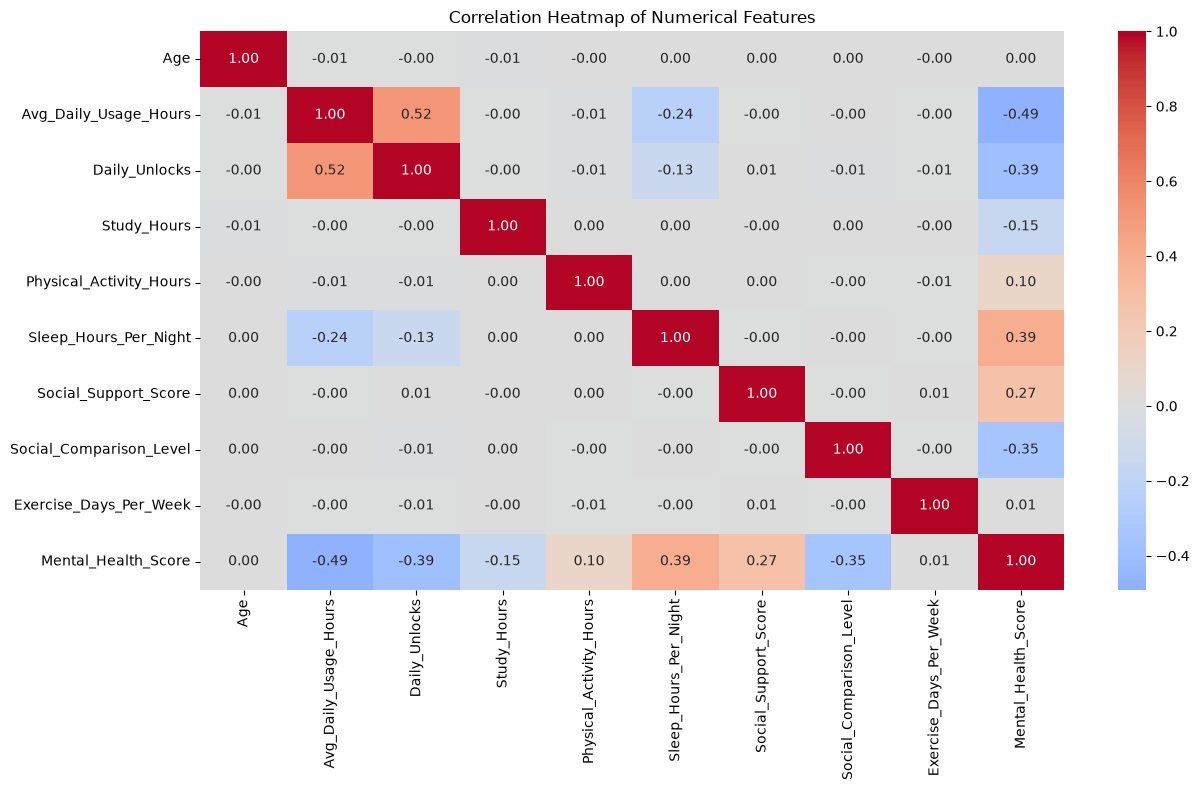

In [9]:
numeric_eda_cols = df.select_dtypes(include=np.number).columns
plt.figure(figsize=(13, 8))
sns.heatmap(df[numeric_eda_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

##### Average Mental Health Score by Platform

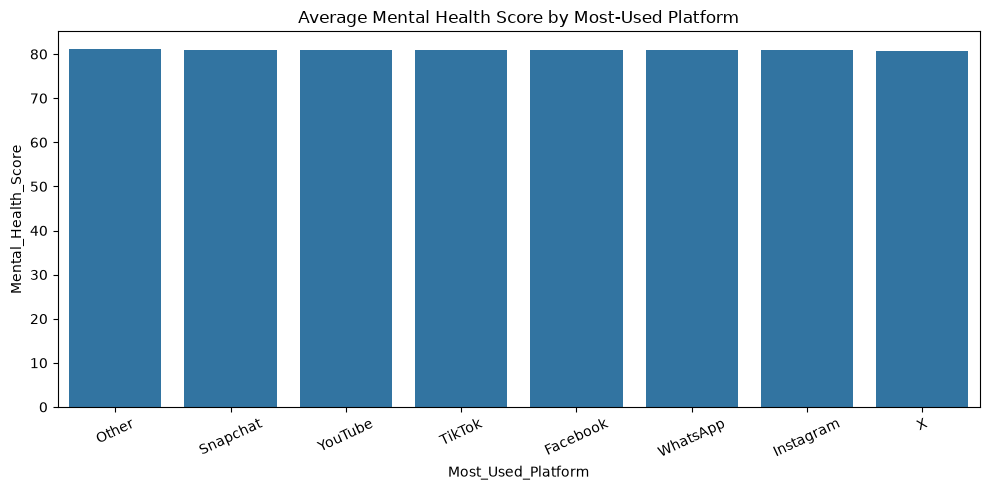

In [10]:
platform_score = df.groupby("Most_Used_Platform", as_index=False)["Mental_Health_Score"].mean().sort_values("Mental_Health_Score", ascending=False)
plt.figure(figsize=(10, 5))
sns.barplot(data=platform_score, x="Most_Used_Platform", y="Mental_Health_Score")
plt.title("Average Mental Health Score by Most-Used Platform")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

##### Stress-Level Distribution and Target Comparison

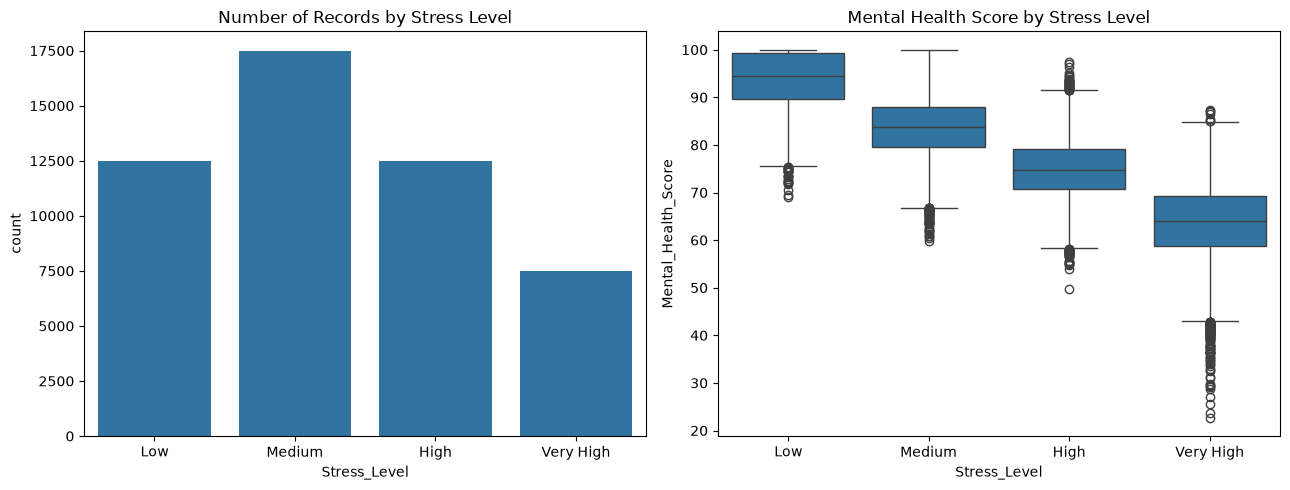

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
stress_order = [v for v in ["Low", "Medium", "High"] if v in df["Stress_Level"].dropna().unique()] + [v for v in sorted(df["Stress_Level"].dropna().unique()) if v not in ["Low", "Medium", "High"]]
sns.countplot(data=df, x="Stress_Level", order=stress_order, ax=axes[0])
axes[0].set_title("Number of Records by Stress Level")
sns.boxplot(data=df, x="Stress_Level", y="Mental_Health_Score", order=stress_order, ax=axes[1])
axes[1].set_title("Mental Health Score by Stress Level")
plt.tight_layout()
plt.show()

##### Pairwise Patterns (Sample of the Dataset)

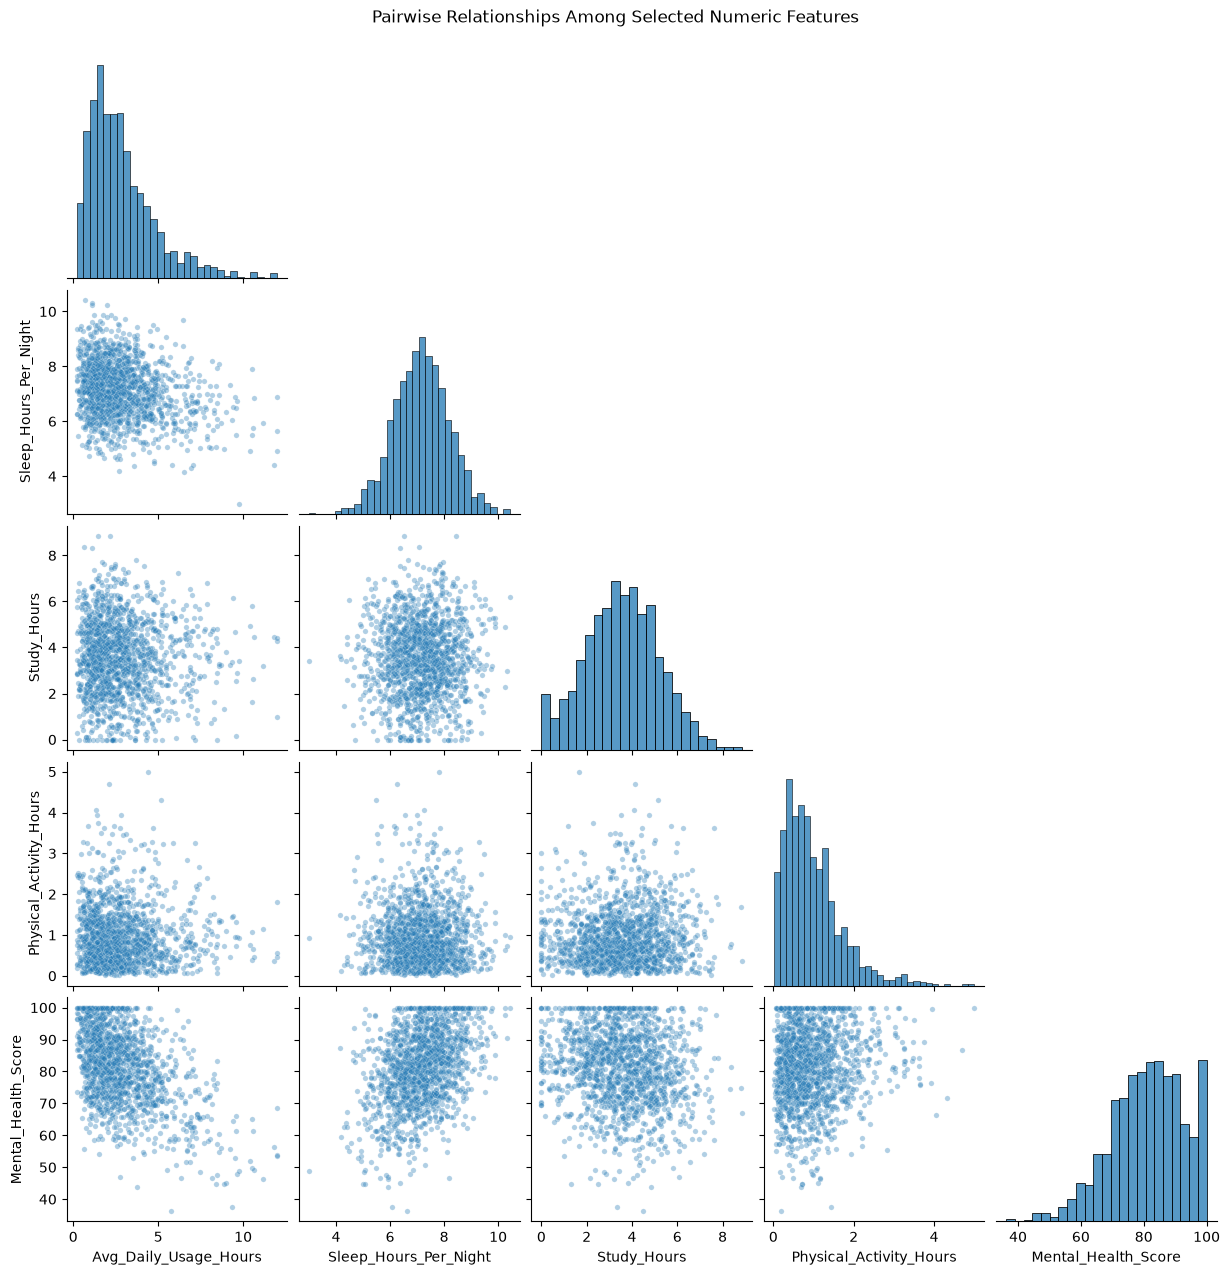

In [12]:
pairplot_cols = ["Avg_Daily_Usage_Hours", "Sleep_Hours_Per_Night", "Study_Hours", "Physical_Activity_Hours", "Mental_Health_Score"]
pairplot_sample = df[pairplot_cols].sample(n=min(1500, len(df)), random_state=23)
sns.pairplot(pairplot_sample, corner=True, diag_kind="hist", plot_kws={"alpha": 0.35, "s": 15})
plt.suptitle("Pairwise Relationships Among Selected Numeric Features", y=1.02)
plt.show()

### Data Preprocessing

In [13]:
x = df.drop(columns=["Mental_Health_Score"])
y = df["Mental_Health_Score"]

from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, train_size=0.8, random_state=23)

In [14]:
nominal_cols = ["Gender", "Country", "Most_Used_Platform", "Purpose_Of_Use", "Cyberbullying_Exposure"]

ordinal_cols = ["Academic_Level", "Stress_Level"]
academic_level_order = ["High School", "Undergraduate", "Graduate", "Postgraduate"]
stress_level_order = ["Low", "Medium", "High"]

numerical_cols = ["Age", "Avg_Daily_Usage_Hours", "Daily_Unlocks", "Study_Hours", "Physical_Activity_Hours", "Sleep_Hours_Per_Night", "Social_Support_Score", "Social_Comparison_Level", "Exercise_Days_Per_Week"]

print("Nominal columns:", nominal_cols)
print("Ordinal columns:", ordinal_cols)
print("Numerical columns:", numerical_cols)

Nominal columns: ['Gender', 'Country', 'Most_Used_Platform', 'Purpose_Of_Use', 'Cyberbullying_Exposure']
Ordinal columns: ['Academic_Level', 'Stress_Level']
Numerical columns: ['Age', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks', 'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night', 'Social_Support_Score', 'Social_Comparison_Level', 'Exercise_Days_Per_Week']


In [15]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import RFE
from sklearn.tree import DecisionTreeRegressor

In [16]:
nominal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [17]:
nominal_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('encoder', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'most_frequent'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto ac

In [18]:
ordinal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        categories=[academic_level_order, stress_level_order],
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))
])


In [19]:
ordinal_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('encoder', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'most_frequent'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto ac

In [20]:
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


In [21]:
numerical_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account fo

In [22]:
Data_preprocessing = ColumnTransformer([
    ("Nominal Transformation", nominal_pipeline, nominal_cols),
    ("Ordinal Transformation", ordinal_pipeline, ordinal_cols),
    ("Numerical Transformation", numerical_pipeline, numerical_cols)
])


In [23]:
Data_preprocessing

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Nominal Transformation', ...), ('Ordinal Transformation', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names

### Feature Selection — Recursive Feature Elimination (RFE)

In [24]:
def make_feature_selector():
    return RFE(
        estimator=DecisionTreeRegressor(max_depth=6, random_state=23),
        n_features_to_select=10,
        step=0.1
    )


### Model Building

### Linear regression

In [25]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

linear_model = Pipeline([
    ("Data Preprocessing", Data_preprocessing),
    ("Feature Selection", make_feature_selector()),
    ("Algorithm", LinearRegression())
])
linear_model.fit(x_train, y_train)
y_pred = linear_model.predict(x_test)
print("R2 Score :", r2_score(y_test, y_pred))
print("MAE :", mean_absolute_error(y_test, y_pred))
print("RMSE :", np.sqrt(mean_squared_error(y_test, y_pred)))

R2 Score : 0.6205003705971162
MAE : 5.85271753709881
RMSE : 7.303712010807296


In [26]:
x_training = linear_model.predict(x_train)
x_testing = linear_model.predict(x_test)

train_r2 = r2_score(y_train,x_training)
test_r2 = r2_score(y_test,x_testing)

print("Train R2 Score:",train_r2)
print("Test R2 Score:",test_r2)

Train R2 Score: 0.622098252726545
Test R2 Score: 0.6205003705971162


### Decision Tree

In [28]:
from sklearn.tree import DecisionTreeRegressor

dt_model = Pipeline([
    ("Data Preprocessing", Data_preprocessing),
    ("Feature Selection", make_feature_selector()),
    ("Algorithm", DecisionTreeRegressor(random_state=23))
])
dt_model.fit(x_train, y_train)
y_pred = dt_model.predict(x_test)
print("R2 Score :", r2_score(y_test, y_pred))
print("MAE :", mean_absolute_error(y_test, y_pred))
print("RMSE :", np.sqrt(mean_squared_error(y_test, y_pred)))

R2 Score : 0.48260974601962203
MAE : 6.737179999999999
RMSE : 8.527997889305555


In [29]:
x_training = dt_model.predict(x_train)
x_testing = dt_model.predict(x_test)

train_r2 = r2_score(y_train,x_training)
test_r2 = r2_score(y_test,x_testing)

print("Train R2 Score:",train_r2)
print("Test R2 Score:",test_r2)

Train R2 Score: 1.0
Test R2 Score: 0.48260974601962203


### Random forest

In [30]:
from sklearn.ensemble import RandomForestRegressor

rf_model = Pipeline([
    ("Data Preprocessing", Data_preprocessing),
    ("Feature Selection", make_feature_selector()),
    ("Algorithm", RandomForestRegressor(n_estimators=120, random_state=23, n_jobs=-1))
])
rf_model.fit(x_train, y_train)
y_pred = rf_model.predict(x_test)
print("R2 Score :", r2_score(y_test, y_pred))
print("MAE :", mean_absolute_error(y_test, y_pred))
print("RMSE :", np.sqrt(mean_squared_error(y_test, y_pred)))

R2 Score : 0.7370894125471221
MAE : 4.87848475
RMSE : 6.0791379704771655


In [31]:
x_training = rf_model.predict(x_train)
x_testing = rf_model.predict(x_test)

train_r2 = r2_score(y_train,x_training)
test_r2 = r2_score(y_test,x_testing)

print("Train R2 Score:",train_r2)
print("Test R2 Score:",test_r2)

Train R2 Score: 0.9620334181088197
Test R2 Score: 0.7370894125471221


### SVR

In [32]:
from sklearn.svm import SVR

svr_model = Pipeline([
    ("Data Preprocessing", Data_preprocessing),
    ("Feature Selection", make_feature_selector()),
    ("Algorithm", SVR())
])
svr_model.fit(x_train, y_train)
y_pred = svr_model.predict(x_test)
print("R2 Score :", r2_score(y_test, y_pred))
print("MAE :", mean_absolute_error(y_test, y_pred))
print("RMSE :", np.sqrt(mean_squared_error(y_test, y_pred)))

R2 Score : 0.7294836116573529
MAE : 4.896677252957884
RMSE : 6.1664434428813175


In [33]:
x_training = svr_model.predict(x_train)
x_testing = svr_model.predict(x_test)

train_r2 = r2_score(y_train,x_training)
test_r2 = r2_score(y_test,x_testing)

print("Train R2 Score:",train_r2)
print("Test R2 Score:",test_r2)

Train R2 Score: 0.7302746623161855
Test R2 Score: 0.7294836116573529


### KNN

In [34]:
from sklearn.neighbors import KNeighborsRegressor

knn_model = Pipeline([
    ("Data Preprocessing", Data_preprocessing),
    ("Feature Selection", make_feature_selector()),
    ("Algorithm", KNeighborsRegressor())
])
knn_model.fit(x_train, y_train)
y_pred = knn_model.predict(x_test)
print("R2 Score :", r2_score(y_test, y_pred))
print("MAE :", mean_absolute_error(y_test, y_pred))
print("RMSE :", np.sqrt(mean_squared_error(y_test, y_pred)))

R2 Score : 0.6891684408345242
MAE : 5.267586
RMSE : 6.609985636898162


In [35]:
x_training = knn_model.predict(x_train)
x_testing = knn_model.predict(x_test)

train_r2 = r2_score(y_train,x_training)
test_r2 = r2_score(y_test,x_testing)

print("Train R2 Score:",train_r2)
print("Test R2 Score:",test_r2)

Train R2 Score: 0.7929817313599451
Test R2 Score: 0.6891684408345242


### XGBoost

In [30]:
from xgboost import XGBRegressor

xg_model = Pipeline([
    ("Data Preprocessing", Data_preprocessing),
    ("Feature Selection", make_feature_selector()),
    ("Algorithm", XGBRegressor(
        n_estimators=120, max_depth=4, learning_rate=0.05,
        objective="reg:squarederror", random_state=23, n_jobs=-1
    ))
])
xg_model.fit(x_train, y_train)
y_pred = xg_model.predict(x_test)
print("R2 Score :", r2_score(y_test, y_pred))
print("MAE :", mean_absolute_error(y_test, y_pred))
print("RMSE :", np.sqrt(mean_squared_error(y_test, y_pred)))

R2 Score : 0.7448829668827447
MAE : 4.805611987762451
RMSE : 5.988357095910125


In [31]:
x_training = xg_model.predict(x_train)
x_testing = xg_model.predict(x_test)

train_r2 = r2_score(y_train,x_training)
test_r2 = r2_score(y_test,x_testing)

print("Train R2 Score:",train_r2)
print("Test R2 Score:",test_r2)

Train R2 Score: 0.7483645917808043
Test R2 Score: 0.7448829668827447


### Cross Validation

In [32]:
from sklearn.model_selection import KFold, cross_val_score
kf = KFold(n_splits=5, shuffle=True, random_state=23)
cross_val_score(xg_model, x_train, y_train, scoring="r2", cv=kf).mean()

np.float64(0.7389189722752418)

### HyperparameterTuning

In [33]:
from sklearn.model_selection import RandomizedSearchCV
search_space = {"Algorithm__n_estimators": [100, 150, 200], "Algorithm__max_depth": [3, 4, 5], "Algorithm__learning_rate": [0.03, 0.05, 0.1], "Algorithm__subsample": [0.8, 1.0]}
rsv = RandomizedSearchCV(estimator=xg_model, param_distributions=search_space, n_iter=6, cv=kf, scoring="r2", random_state=23, n_jobs=-1)
rsv.fit(x_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'Algorithm__learning_rate': [0.03, 0.05, ...], 'Algorithm__max_depth': [3, 4, ...], 'Algorithm__n_estimators': [100, 150, ...], 'Algorithm__subsample': [0.8, 1.0]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",6
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",23
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict

In [34]:
rsv.best_params_

{'Algorithm__subsample': 0.8,
 'Algorithm__n_estimators': 200,
 'Algorithm__max_depth': 3,
 'Algorithm__learning_rate': 0.05}

In [35]:
rsv.best_score_

np.float64(0.740318721235004)

### Final Model

In [36]:
final_model = rsv.best_estimator_
final_model.fit(x_train, y_train)
y_pred = final_model.predict(x_test)
print("Test R2 Score :", r2_score(y_test, y_pred))
print("Test MAE :", mean_absolute_error(y_test, y_pred))
print("Test RMSE :", np.sqrt(mean_squared_error(y_test, y_pred)))

Test R2 Score : 0.7461580976473617
Test MAE : 4.788530032272338
Test RMSE : 5.973372789076668


In [38]:
final_model.fit(x, y)
with open(r"C:\Users\LENOVO\Desktop\streamlit\Social media and mental well being\regression.pkl", "wb") as f:
    pickle.dump(final_model, f)
print("Regression model saved successfully")

Regression model saved successfully
